# Phase 2 - MOMENT Encoder

Swaps Hilders' LSTM encoder for a frozen MOMENT time-series foundation model.


## Imports

In [18]:
import os
import warnings
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm
from functools import partial

from sklearn.metrics import accuracy_score, roc_auc_score, mean_squared_error

from momentfm import MOMENTPipeline

pd.set_option('display.max_columns', None)


## Config



In [19]:
FEATURES_INCLUDED = [
    'ast', 'alt', 'bicarbonate', 'bilirubin', 'bun', 'calcium', 'chloride',
    'potassium', 'creatinine', 'glucose', 'heart_rate', 'hematocrit', 'hemoglobin',
    'lactate', 'spo2', 'pao2', 'paco2', 'ph', 'platelet', 'resp_rate',
    'sodium', 'sysbp', 'meanbp', 'diasbp', 'tempc', 'wbc', 'gcs_eye',
    'gcs_motor', 'admission_age_norm', 'weight_norm', 'height_norm',
    'weight_null', 'height_null', 'gender'
]

OUTCOMES_INCLUDED = [
    '90day_mortality',
    'LOS_remaining_days',
    'rrt_next_timestep',
    'mv_next_timestep'
]

UNIQUE_STAY_ID = 'admissionid'
CACHE_DIR = Path('data/moment_cache')
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print(f'{len(FEATURES_INCLUDED)} input features')


34 input features


In [20]:
# from icu_dataset.py
class ICUDataset(Dataset):
    def __init__(self, data, features, outcomes, unique_stay_id='admissionid'):
        self.data = data
        self.vo_ids = data[unique_stay_id].unique()
        self.features = features
        self.outcomes = outcomes
        self.unique_stay_id = unique_stay_id

    def __len__(self):
        return len(self.vo_ids)

    def __getitem__(self, idx):
        visit_id = self.vo_ids[idx]
        patient_data = self.data[self.data[self.unique_stay_id] == visit_id]
        sequence = patient_data[self.features].values
        labels = patient_data[self.outcomes].values

        return torch.tensor(sequence, dtype=torch.float32), torch.tensor(labels, dtype=torch.float32)


def custom_collate_fn(batch):
    X, y = list(zip(*batch))
    return X, y


In [21]:
MOMENT_MODEL_NAME = 'AutonLab/MOMENT-1-base'
CONTEXT_LENGTH = 512
PATCH_LENGTH = 8

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## MOMENT feature extractor 

ClaudeAI. Prompt- wrap moment so it takes our raw sequences and gives back embeddings, frozen

In [22]:
class MOMENTFeatureExtractor(nn.Module):
    """Frozen MOMENT wrapper used only to build the embedding cache."""

    def __init__(self, model_name=MOMENT_MODEL_NAME, context_length=CONTEXT_LENGTH,
                 patch_length=PATCH_LENGTH, device='cpu'):
        super().__init__()
        self.device = device
        self.context_length = context_length
        self.patch_length = patch_length
        self.n_patches = context_length // patch_length

        self.moment = MOMENTPipeline.from_pretrained(
            model_name,
            model_kwargs={'task_name': 'embedding'}
        )
        self.moment.init()
        self.moment = self.moment.to(self.device)
        self.moment.eval()
        for param in self.moment.parameters():
            param.requires_grad = False

        # disable gradient checkpointing directly (calling .disable() alone didn't
        # stop the warnings in testing -- setting the attribute is more robust)
        if hasattr(self.moment.encoder, 'gradient_checkpointing'):
            self.moment.encoder.gradient_checkpointing = False
        if hasattr(self.moment.encoder, 'gradient_checkpointing_disable'):
            self.moment.encoder.gradient_checkpointing_disable()

        warnings.filterwarnings('ignore', message='.*use_reentrant parameter.*')
        warnings.filterwarnings('ignore', message='.*None of the inputs have requires_grad.*')

    def _pad_and_mask(self, sequence):
        seq_len = sequence.shape[0]
        if seq_len >= self.context_length:
            padded = sequence[:self.context_length]
            mask = torch.ones(self.context_length)
            orig_len = self.context_length
        else:
            pad_len = self.context_length - seq_len
            padded = torch.cat([sequence, torch.zeros(pad_len, sequence.shape[1])], dim=0)
            mask = torch.cat([torch.ones(seq_len), torch.zeros(pad_len)])
            orig_len = seq_len
        return padded, mask, orig_len

    def forward(self, input):
        """input: list of (seq_len_i, n_features) raw feature tensors.
        Returns (pooled_embeddings, orig_lens): (batch, n_patches, moment_dim) and (batch,).
        """
        batch_size = len(input)
        n_features = input[0].shape[1]

        padded_seqs, masks, orig_lens = [], [], []
        for seq in input:
            padded, mask, orig_len = self._pad_and_mask(seq)
            padded_seqs.append(padded)
            masks.append(mask)
            orig_lens.append(orig_len)

        x = torch.stack(padded_seqs).to(self.device)
        mask = torch.stack(masks).to(self.device)
        x_enc = x.permute(0, 2, 1)  # (batch, n_features, context_length)

        with torch.no_grad():
            moment_out = self.moment(x_enc=x_enc, input_mask=mask, reduction='none')
            patch_embeddings = moment_out.embeddings  # (batch, n_channels, n_patches, moment_dim)

        pooled = patch_embeddings.mean(dim=1)  # (batch, n_patches, moment_dim)
        orig_lens_capped = torch.tensor([min(l, self.context_length) for l in orig_lens])

        return pooled.cpu(), orig_lens_capped


## Load pre-split data

In [ ]:
DATA_DIR = '../data/splits'

train_data = pd.read_csv(f'{DATA_DIR}/train.csv')
val_data = pd.read_csv(f'{DATA_DIR}/val.csv')
test_data = pd.read_csv(f'{DATA_DIR}/test.csv')

print(f'Train: {train_data.shape}, {train_data.admissionid.nunique()} admissions')
print(f'Val:   {val_data.shape}, {val_data.admissionid.nunique()} admissions')
print(f'Test:  {test_data.shape}, {test_data.admissionid.nunique()} admissions')


## Precompute and cache MOMENT embeddings (run once)

ClaudeAI. Prompt- Write a function that runs the whole train/val/test set through that MOMENT extractor once and saves the embeddings to disk.

In [ ]:
PRECOMPUTE_BATCH_SIZE = 32
FORCE_RECOMPUTE = True

feature_extractor = MOMENTFeatureExtractor(device=device)
print(f'MOMENT embedding dim: inferring from a dummy pass...')
with torch.no_grad():
    _dummy_out, _ = feature_extractor([torch.zeros(10, len(FEATURES_INCLUDED))])
MOMENT_DIM = _dummy_out.shape[-1]
print(f'MOMENT_DIM = {MOMENT_DIM}')


def precompute_and_cache_embeddings(data_df, features, extractor, cache_path, batch_size, unique_stay_id='admissionid'):
    if cache_path.exists() and not FORCE_RECOMPUTE:
        print(f'{cache_path} already exists, skipping (set FORCE_RECOMPUTE=True to redo)')
        return

    raw_dataset = ICUDataset(data_df, features, outcomes=[], unique_stay_id=unique_stay_id)
    admission_ids = list(raw_dataset.vo_ids)  # preserve exact iteration order
    loader = DataLoader(raw_dataset, batch_size=batch_size, shuffle=False, collate_fn=custom_collate_fn)

    all_embeddings, all_orig_lens = [], []
    with torch.no_grad():
        for X, _ in tqdm(loader, desc=f'Precomputing {cache_path.stem}'):
            pooled, orig_lens = extractor(X)
            all_embeddings.append(pooled)
            all_orig_lens.append(orig_lens)

    embeddings = torch.cat(all_embeddings, dim=0)
    orig_lens = torch.cat(all_orig_lens, dim=0)

    torch.save({
        'admission_ids': admission_ids,
        'embeddings': embeddings,
        'orig_lens': orig_lens,
        'moment_dim': embeddings.shape[-1]
    }, cache_path)
    print(f'Saved {len(admission_ids)} embeddings to {cache_path}, shape {tuple(embeddings.shape)}')


start = time.time()
precompute_and_cache_embeddings(train_data, FEATURES_INCLUDED, feature_extractor, CACHE_DIR / 'train_embeddings.pt', PRECOMPUTE_BATCH_SIZE)
precompute_and_cache_embeddings(val_data, FEATURES_INCLUDED, feature_extractor, CACHE_DIR / 'val_embeddings.pt', PRECOMPUTE_BATCH_SIZE)
precompute_and_cache_embeddings(test_data, FEATURES_INCLUDED, feature_extractor, CACHE_DIR / 'test_embeddings.pt', PRECOMPUTE_BATCH_SIZE)
print(f'Total precompute time: {time.time() - start:.1f}s')


## Predictor heads and SGROUP_Network

Unchanged from Phase 1 notebook-6.

In [25]:
class ExponentialActivation(nn.Module):
    def forward(self, input):
        return torch.exp(input)


ACTIVATION_DICT = {
    'sigmoid': nn.Sigmoid(),
    'exp': ExponentialActivation()
}


class MLP_Predictor(nn.Module):
    def __init__(self, encoder_dim, output_dim, output_activation=None, device='cpu'):
        super().__init__()
        self.device = device
        intermediate_dim = encoder_dim // 2

        layers = [
            nn.Linear(encoder_dim, intermediate_dim),
            nn.BatchNorm1d(intermediate_dim),
            nn.ReLU(),
            nn.Linear(intermediate_dim, output_dim)
        ]
        if output_activation is not None:
            layers.append(ACTIVATION_DICT[output_activation])

        self.network = nn.Sequential(*layers).to(self.device)

    def forward(self, input):
        input = input.to(self.device)
        batch_size, seq_len, feature_dim = input.shape
        input = input.view(-1, feature_dim)

        output = self.network(input)
        output = output.view(batch_size, seq_len, -1)

        return output


In [26]:
class SGROUP_Network(nn.Module):
    ALL_CRITERIA = {
        'mortality': {
            'criterion': nn.BCEWithLogitsLoss(reduction='none'),
            'weight': 1.0, 'is_binary': True, 'output_config': (1, None)
        },
        'LOS': {
            'criterion': nn.MSELoss(reduction='none'),
            'weight': 0.001, 'is_binary': False, 'output_config': (1, 'exp')
        },
        'rrt': {
            'criterion': nn.BCEWithLogitsLoss(reduction='none'),
            'weight': 0.25, 'is_binary': True, 'output_config': (1, None)
        },
        'mv': {
            'criterion': nn.BCEWithLogitsLoss(reduction='none'),
            'weight': 0.25, 'is_binary': True, 'output_config': (1, None)
        }
    }

    def __init__(self, input_dim, hidden_dim, outcomes=['mortality'],
                 encoder_class=None, predictor_class=MLP_Predictor,
                 num_encoder_layers=3, device='cpu'):
        super().__init__()
        self.device = device
        self.outcomes = outcomes
        self.encoder = encoder_class(input_dim, hidden_dim, num_layers=num_encoder_layers, device=self.device)

        self.criteria = {key: self.ALL_CRITERIA[key] for key in outcomes}

        self.predictors = nn.ModuleList([
            predictor_class(
                hidden_dim,
                self.criteria[key]['output_config'][0],
                output_activation=self.criteria[key]['output_config'][1],
                device=self.device
            )
            for key in outcomes
        ])

    def forward(self, input):
        encoding, output, output_lens = self.encoder(input)
        predictions = [predictor(output) for predictor in self.predictors]
        return encoding, output, output_lens, predictions

    def compute_loss(self, preds, labels, lengths):
        losses = {key: [] for key in self.criteria.keys()}

        for i, length in enumerate(lengths):
            for j, (key, value) in enumerate(self.criteria.items()):
                criterion = value['criterion']
                weight = value['weight']
                pred = preds[j][i][:length].squeeze(-1)
                label = labels[i][:length, j].float().to(self.device)

                loss = criterion(pred, label).mean()
                losses[key].append(loss * weight)

        mean_weighted_losses = [torch.mean(torch.stack(loss_list)) for loss_list in losses.values()]
        return torch.mean(torch.stack(mean_weighted_losses))

    def initialise_result_dict(self):
        results = {}
        for key, value in self.criteria.items():
            if value['is_binary']:
                results[key] = {'accuracy': [], 'labels': [], 'preds': []}
            else:
                results[key] = {'mse': []}
        return results

    def compile_results(self, results):
        compiled_results = {}
        for key, value in self.criteria.items():
            metrics = results[key]
            if value['is_binary']:
                compiled_results[f'{key}_acc'] = np.mean(metrics['accuracy'])
                if len(np.unique(metrics['labels'])) > 1:
                    mean_auroc = roc_auc_score(metrics['labels'], metrics['preds'])
                else:
                    mean_auroc = float('nan')
                compiled_results[f'{key}_auroc'] = np.mean(mean_auroc)
            else:
                compiled_results[f'{key}_mse'] = np.mean(metrics['mse'])
        return compiled_results

    def compute_metrics(self, preds, labels, lengths):
        results = self.initialise_result_dict()

        for i, length in enumerate(lengths):
            for j, (key, value) in enumerate(self.criteria.items()):
                valid_preds = preds[j][i][:length].squeeze(-1)
                valid_labels = labels[i][:length, j].float()

                if value['is_binary']:
                    pred_probs = torch.sigmoid(valid_preds)
                    pred_binary = (pred_probs > 0.5).float().cpu().detach().numpy().flatten()
                    labels_binary = valid_labels.cpu().numpy().flatten()

                    results[key]['accuracy'].append(accuracy_score(labels_binary, pred_binary))
                    results[key]['preds'].extend(pred_probs.cpu().detach().numpy().flatten())
                    results[key]['labels'].extend(labels_binary)
                else:
                    mse_value = mean_squared_error(valid_labels.cpu().numpy(), valid_preds.cpu().detach().numpy())
                    results[key]['mse'].append(mse_value)

        return self.compile_results(results)


## Cached MOMENT encoder (fast, used during training)

ClaudeAI. Prompt- Need a class same as LSTM encoder interface but just loads the cache and projects it down

In [27]:
class CachedMOMENT_Encoder(nn.Module):
    """input: (embeddings_batch, orig_lens_batch) from CachedEmbeddingDataset/cached_collate_fn.

    input_dim is unused (kept for interface parity with LSTM_Encoder / MOMENTFeatureExtractor).
    moment_dim must be passed explicitly (read from the cache file) since this class never
    loads MOMENT itself and can't infer it.
    """

    def __init__(self, input_dim, hidden_dim, num_layers=None, device='cpu',
                 moment_dim=None, patch_length=PATCH_LENGTH):
        super().__init__()
        self.device = device
        self.patch_length = patch_length

        if moment_dim is None:
            raise ValueError('moment_dim must be provided -- read it from the cache file (see MOMENT_DIM above)')

        self.projection = nn.Linear(moment_dim, hidden_dim).to(self.device)

    def forward(self, input, input_padded=False):
        embeddings_batch, orig_lens_batch = input
        embeddings_batch = embeddings_batch.to(self.device)

        projected = self.projection(embeddings_batch)                      # (batch, n_patches, hidden_dim)
        output = projected.repeat_interleave(self.patch_length, dim=1)     # (batch, n_patches * patch_length, hidden_dim)

        encoding = output
        return encoding, output, orig_lens_batch


## Cached embedding dataset

ClaudeAI. Prompt- dataset that loads the cache and matches it to labels like ICUDataset does

In [28]:
class CachedEmbeddingDataset(Dataset):
    def __init__(self, cache_path, raw_data, outcomes, unique_stay_id='admissionid'):
        cache = torch.load(cache_path, weights_only=False)
        self.admission_ids = cache['admission_ids']
        self.embeddings = cache['embeddings']    # (n_admissions, n_patches, moment_dim)
        self.orig_lens = cache['orig_lens']      # (n_admissions,)
        self.raw_data = raw_data
        self.outcomes = outcomes
        self.unique_stay_id = unique_stay_id

    def __len__(self):
        return len(self.admission_ids)

    def __getitem__(self, idx):
        admission_id = self.admission_ids[idx]
        embedding = self.embeddings[idx]
        orig_len = int(self.orig_lens[idx].item())

        patient_data = self.raw_data[self.raw_data[self.unique_stay_id] == admission_id]
        labels = torch.tensor(patient_data[self.outcomes].values, dtype=torch.float32)

        return embedding, orig_len, labels


def cached_collate_fn(batch):
    embeddings, orig_lens, labels = zip(*batch)
    embeddings_batch = torch.stack(embeddings)       # fixed size (n_patches, moment_dim) per admission -- safe to stack
    orig_lens_batch = torch.tensor(orig_lens)
    labels = list(labels)                            # variable length -- kept as list, matches compute_loss's per-i slicing
    return (embeddings_batch, orig_lens_batch), labels


## Build cached datasets & dataloaders


In [ ]:
BATCH_SIZE = 256

train_dataset = CachedEmbeddingDataset(CACHE_DIR / 'train_embeddings.pt', train_data, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)
val_dataset = CachedEmbeddingDataset(CACHE_DIR / 'val_embeddings.pt', val_data, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)
test_dataset = CachedEmbeddingDataset(CACHE_DIR / 'test_embeddings.pt', test_data, OUTCOMES_INCLUDED, unique_stay_id=UNIQUE_STAY_ID)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=cached_collate_fn)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=cached_collate_fn)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=cached_collate_fn)

print(f'{len(train_dataset)} train / {len(val_dataset)} val / {len(test_dataset)} test patients')

# sanity check one batch
(X_emb, X_lens), y_batch = next(iter(train_dataloader))
print(f'Embeddings batch shape: {X_emb.shape}')
print(f'Orig lens: {X_lens[:10]}...')


## Training utilities

Same as Phase 1 notebook-6. 

In [30]:
def set_seeds(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)


def run_epoch(model, dataloader, device, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    epoch_losses = []
    epoch_metrics = []

    desc = 'Training' if is_train else 'Validation'
    grad_context = torch.enable_grad() if is_train else torch.no_grad()

    with grad_context:
        with tqdm(total=len(dataloader), desc=desc, unit='batch', mininterval=2.0) as pbar:
            for X, y in dataloader:
                if is_train:
                    optimizer.zero_grad()

                encoding, output, output_lens, predictions = model(X)
                loss = model.compute_loss(predictions, y, output_lens)

                if is_train:
                    loss.backward()
                    torch.nn.utils.clip_grad_norm_(
                        [p for p in model.parameters() if p.requires_grad], max_norm=1.0
                    )
                    optimizer.step()

                metrics = model.compute_metrics(predictions, y, output_lens)
                epoch_losses.append(loss.item())
                epoch_metrics.append(metrics)

                pbar.set_postfix(loss=loss.item(), **metrics)
                pbar.update()

    avg_loss = float(np.mean(epoch_losses))
    avg_metrics = {k: float(np.nanmean([m[k] for m in epoch_metrics])) for k in epoch_metrics[0]}
    return avg_loss, avg_metrics


In [ ]:
test_id = 160.0
match = train_dataset.raw_data[train_dataset.raw_data['admissionid'] == test_id]
print(f'Rows found for {test_id}: {len(match)}')
print(test_id in set(train_dataset.admission_ids))
print(test_id in set(train_data['admissionid'].unique()))

In [ ]:
from pathlib import Path
print(Path('../data/moment_cache').resolve())
print(Path('../data/moment_cache').exists())

## Train the model


In [ ]:
SEED = 42
EMBEDDING_SIZE = 32  # projection target dim, matches LSTM baseline for fair comparison
LEARNING_RATE = 0.001
N_EPOCHS = 150
CHECKPOINT_INTERVAL = 10
SAVE_FOLDER = Path('model_checkpoints/moment_baseline')
SAVE_FOLDER.mkdir(parents=True, exist_ok=True)

set_seeds(SEED)

model = SGROUP_Network(
    input_dim=len(FEATURES_INCLUDED),
    hidden_dim=EMBEDDING_SIZE,
    outcomes=['mortality', 'LOS', 'rrt', 'mv'],
    encoder_class=partial(CachedMOMENT_Encoder, moment_dim=MOMENT_DIM),
    device=device
).to(device)

trainable_params = [p for p in model.parameters() if p.requires_grad]
print(f'{sum(p.numel() for p in trainable_params)} trainable parameters (projection + predictor heads)')

optimizer = optim.Adam(trainable_params, lr=LEARNING_RATE)

history = []
best_val_auroc = -1.0
best_epoch = -1
best_path = SAVE_FOLDER / 'SGROUPmodel_moment_best.pth'

for epoch in range(N_EPOCHS):
    train_loss, train_metrics = run_epoch(model, train_dataloader, device, optimizer)
    val_loss, val_metrics = run_epoch(model, val_dataloader, device)

    metrics_str = ' | '.join(f'{k}: {train_metrics[k]:.4f}/{val_metrics[k]:.4f}' for k in train_metrics)
    print(f'Epoch [{epoch + 1}/{N_EPOCHS}] Loss: {train_loss:.4f}/{val_loss:.4f} {metrics_str}')

    history.append({
        'epoch': epoch + 1, 'train_loss': train_loss, 'val_loss': val_loss,
        **{f'train_{k}': v for k, v in train_metrics.items()},
        **{f'val_{k}': v for k, v in val_metrics.items()}
    })

    if val_metrics['mortality_auroc'] > best_val_auroc:
        best_val_auroc = val_metrics['mortality_auroc']
        best_epoch = epoch + 1
        torch.save(model.state_dict(), best_path)

    if (epoch + 1) % CHECKPOINT_INTERVAL == 0:
        checkpoint_path = SAVE_FOLDER / f'SGROUPmodel_moment_Epoch{epoch + 1}_of_{N_EPOCHS}.pth'
        torch.save(model.state_dict(), checkpoint_path)

final_path = SAVE_FOLDER / f'SGROUPmodel_moment_Epochs{N_EPOCHS}_final.pth'
torch.save(model.state_dict(), final_path)
print(f'Saved final checkpoint to {final_path}')
print(f'Best val mortality_auroc: {best_val_auroc:.4f} at epoch {best_epoch}, saved to {best_path}')

history_df = pd.DataFrame(history)
history_df.to_csv(SAVE_FOLDER / 'training_history.csv', index=False)


## Training curve


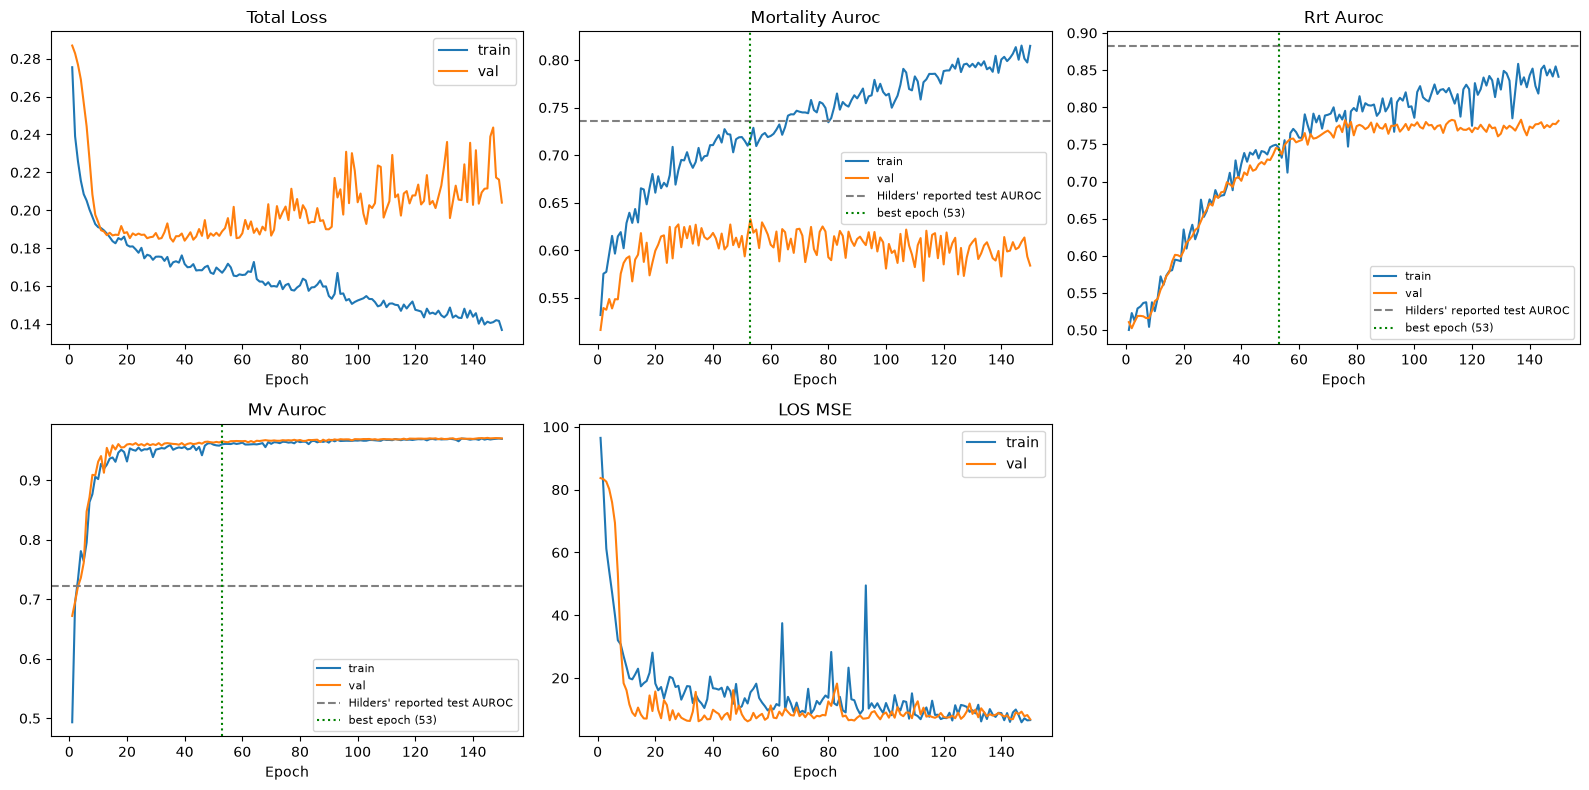

In [33]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

axes[0, 0].plot(history_df['epoch'], history_df['train_loss'], label='train')
axes[0, 0].plot(history_df['epoch'], history_df['val_loss'], label='val')
axes[0, 0].set_title('Total Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].legend()

auroc_panels = [
    ('mortality_auroc', axes[0, 1], 0.736),
    ('rrt_auroc', axes[0, 2], 0.883),
    ('mv_auroc', axes[1, 0], 0.723),
]
for key, ax, hilders_val in auroc_panels:
    ax.plot(history_df['epoch'], history_df[f'train_{key}'], label='train')
    ax.plot(history_df['epoch'], history_df[f'val_{key}'], label='val')
    ax.axhline(hilders_val, color='gray', linestyle='--', label="Hilders' reported test AUROC")
    ax.axvline(best_epoch, color='green', linestyle=':', label=f'best epoch ({best_epoch})')
    ax.set_title(key.replace('_', ' ').title())
    ax.set_xlabel('Epoch')
    ax.legend(fontsize=8)

axes[1, 1].plot(history_df['epoch'], history_df['train_LOS_mse'], label='train')
axes[1, 1].plot(history_df['epoch'], history_df['val_LOS_mse'], label='val')
axes[1, 1].set_title('LOS MSE')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].legend()

axes[1, 2].axis('off')

plt.tight_layout()
plt.show()


## Test set evaluation

Loads the best checkpoint (by val mortality_auroc) before scoring.

In [34]:
model.load_state_dict(torch.load(best_path, weights_only=True, map_location=device))

test_loss, test_metrics = run_epoch(model, test_dataloader, device)

print(f'Best epoch: {best_epoch} (selected by val mortality_auroc), val mortality_auroc: {best_val_auroc:.4f}')
print(f'Test loss: {test_loss:.4f}')
for k, v in test_metrics.items():
    print(f'  {k}: {v:.4f}')


Validation:   0%|          | 0/2 [00:00<?, ?batch/s]

Best epoch: 53 (selected by val mortality_auroc), val mortality_auroc: 0.6326
Test loss: 0.1902
  mortality_acc: 0.6418
  mortality_auroc: 0.6847
  LOS_mse: 6.1894
  rrt_acc: 0.9480
  rrt_auroc: 0.6669
  mv_acc: 0.9362
  mv_auroc: 0.9694
